# Biogeochemical initial and boundary conditions for an existing regional MOM6 domain

This notebook creates biogeochemical (BGC) initial and boundary conditions for an existing (BYO) regional domain creaetd by [ACCESS-rOM3 demo](https://github.com/COSIMA/regional-mom6/blob/main/demos/ACCESS-rOM3-demo.ipynb). 
The BGC data comes from a global WOMBAT run: 
`/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/`

## Loading the regional-mom6 environment

To use regional-mom6 on gadi, you'll need to include the following in your ARE session:

```
Module directories: /g/data/vk83/staging/modules
Modules: rmom6
```

## Required NCI projects:
You'll need to be a member of the following projects and also add them to the storage of your ARE session, e.g.,

`Storage: gdata/vk83+gdata/rt52+gdata/ik11`


| name | purpose |
|------|---------|
| vk83 | ACCESS-NRI's MOM6 executable |
| ik11 | GEBCO bathymetry data |
| qv56 | JRA river runoff |
| av17 | ERA5 surface forcing data |

Since this demo is necessarily hardcoded for NCI paths and environments, users outside of Australia should look instead at the machine-agnostic demo, or [CROCODILE-CESM](https://github.com/CROCODILE-CESM/) for users in the US.
All output goes into a `bgc` subfolder of your input directory, so none of your existing (physics) files are overwritten.

In [1]:
import warnings
import xarray as xr
import os
import glob
import matplotlib.pyplot as plt
from pathlib import Path
from dask.distributed import Client
import numpy as np
import pandas as pd
import netCDF4
import shutil

warnings.filterwarnings("ignore")
client = Client()
client

import regional_mom6 as rmom6
from regional_mom6.vgrid import VGrid
print("using regional-mom6 version " + rmom6.__version__)

using regional-mom6 version 1.0.4


2026-10-13 18:29:45,661 - distributed.scheduler - WARNING - Detected different `run_spec` for key ('getitem-60bbe4c7b34e13ab16da7cd78644d58c', 60, 0, 0, 0) between two consecutive calls to `update_graph`. This can cause failures and deadlocks down the line. Please ensure unique key names. If you are using a standard dask collections, consider releasing all the data before resubmitting another computation. More details and help can be found at https://github.com/dask/dask/issues/9888. 
Debugging information
---------------------
old task state: released
old run_spec: <Task ('getitem-60bbe4c7b34e13ab16da7cd78644d58c', 60, 0, 0, 0) getitem(...)>
new run_spec: Alias(('getitem-60bbe4c7b34e13ab16da7cd78644d58c', 60, 0, 0, 0)->('concatenate-open_dataset-e-getitem-60bbe4c7b34e13ab16da7cd78644d58c', 60, 0, 0, 0))
old dependencies: {('getitem-3f51a2af311960f721da52d1ae9575b3', 60, 0, 3, 0)}
new dependencies: frozenset({('concatenate-open_dataset-e-getitem-60bbe4c7b34e13ab16da7cd78644d58c', 60, 0

## Step 1: Point to your existing domain, define workspace paths

In [4]:
expt_name = "access-rom3-bgc"

date_range = ["2013-01-01 00:00:00", "2017-12-31 23:59:59"]

import os
import matplotlib.pyplot as plt
from pathlib import Path

import regional_mom6 as rmom6
print("using regional-mom6 version " + rmom6.__version__)


expt_name = "access-rom3-bgc"
project = os.environ["PROJECT"]
user = os.environ["USER"]
scratch = Path(f"/g/data/{project}/{user}")
gdata = Path(f"/g/data/{project}/{user}")

## Place where all the input files already exist
input_dir = f"{gdata}/rom3-inputdirs/{expt_name}/"

## Place where the BGC input files go
bgc_dir = Path(f"{input_dir}/bgc")
## Directory for temporary files we don't need long term, like the raw cut-out BGC files
tmp_dir = Path(f"{bgc_dir}/tmp")

## Directory where we'll be running the experiment from
run_dir = f"{gdata}/rom3-rundirs/{expt_name}/"

## if directories don't exist, create them
for path in (bgc_dir, tmp_dir):
    os.makedirs(str(path), exist_ok=True)

## Get the domain extent from the existing horizontal grid
hgrid = xr.open_dataset(input_dir + "/hgrid.nc")
longitude_extent = [float(hgrid.x.min()), float(hgrid.x.max())]
latitude_extent = [float(hgrid.y.min()), float(hgrid.y.max())]
print(longitude_extent, latitude_extent)

using regional-mom6 version 1.0.4
[143.0, 150.0] [-48.0, -38.95]


## Step 2: Define experinment
We need a copy of `hgrid.nc` in the BGC folder.
There is a bit of a hack there as we need to redefine things to match the experinment setup in the notebook used to buil the physics


In [10]:
shutil.copy2(Path(f"{input_dir}/hgrid.nc"), Path(f"{bgc_dir}/hgrid.nc"))
vgrid = VGrid.from_file(str(input_dir + "/vgrid.nc"), variable_name="zi", variable_type="cell_interface")

expt = rmom6.experiment(
    date_range = date_range,
    hgrid_type = "from_file",
    vgrid_type = vgrid,
    minimum_depth = 10,               
    depth = 4500,
    mom_run_dir = bgc_dir,
    mom_input_dir = bgc_dir,
    boundaries = ["north", "south", "east", "west"],
)

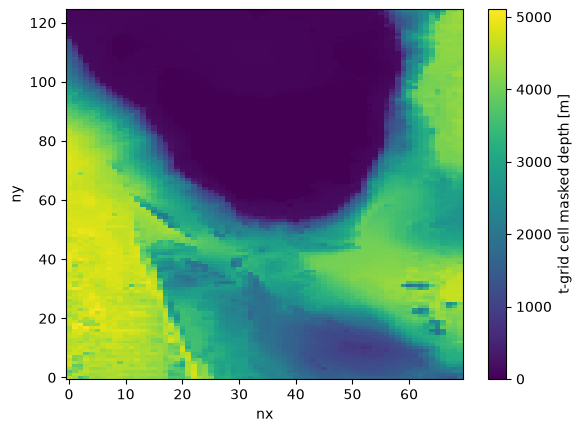

In [12]:
xr.open_dataset(input_dir + "/bathymetry.nc").depth.plot()

## Step 3: Subset BGC  data from global product
Note:
1. BGC tracers are on the model layers (`zl`) and we need to interpolate them onto the layer depths - although Lizzie suggest that this step doesnt really make a difference so we could remove
2. The global model longs are -280 to 80, so we need to offset to get a 0-360 long.
3. I don't think the next 2 cells are not needed if you use the BGC data downloaded from copurnicus - but you may still need to setup some arrays of zeros (or a small seed value) for variables that are missing from copurnicus.

In [28]:
def interfaces_to_centres(da_zi):
    '''
    Interpolating onto depths
    '''
    zl = (da_zi.zi.values[:-1] + da_zi.zi.values[1:]) / 2
    da_zi = da_zi.rename(zi="zl")
    lowers = da_zi.isel(zl=slice(1,None)).assign_coords({"zl": zl})
    uppers = da_zi.isel(zl=slice(None,-1)).assign_coords({"zl": zl})
    da_zl = (lowers + uppers) / 2
    da_zl.zl.attrs["axis"] = "Z"
    return da_zl


def slice_lon(ds, west, east):
    '''
    adding offset to longs
    '''
    shift = 360 if west > 80 else 0
    ds = ds.sel(xh=slice(west - shift, east - shift), xq=slice(west - shift, east - shift))
    return ds.assign_coords(xh=ds.xh + shift, xq=ds.xq + shift)


## Getting one extra time step before and after our timeframe
start = pd.Timestamp(date_range[0]) - pd.DateOffset(months=1)
end = pd.Timestamp(date_range[1]) + pd.DateOffset(months=1)
date_range_s = slice(start.strftime("%Y-%m"), end.strftime("%Y-%m"))
print(date_range_s)

def preprocess(ds):
    return ds.sel(time=date_range_s, drop=True)

buffer = 0.6
wombatlitepath = '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/'

var3d = ['no3','uo+z','vo+z','alk','fe','o2','phy', 'zoo', 'det', 'caco3', 'pchl', 'phyfe', 'zoofe', 'detfe', 'dic','dicp', 'dicr','so+z','thetao+z','e']

var2d = ['zos','det_sediment','caco3_sediment','detfe_sediment']

datasets3d = []
for var_name in var3d:
    print(var_name)
    file_path = os.path.join(wombatlitepath,"output0**", f"access-om3.mom6.3d.{var_name}.1mon.mean.*.nc")
    files = sorted(glob.glob(file_path))
    ds = xr.open_mfdataset(files,preprocess=preprocess,combine="nested",
    concat_dim="time",chunks={"time": 1, "z_l": -1, "zl": -1, "zi": -1, "z_i": -1, "yh": 100, "xh": 100,"yq": 100, "xq": 100})
    datasets3d.append(ds)
access_om2_input3d = xr.merge(datasets3d, join="override", compat="override")

datasets2d = []
for var_name in var2d:
    print(var_name)
    file_path = os.path.join(wombatlitepath,"output0**", f"access-om3.mom6.2d.{var_name}.1mon.mean.*.nc")
    files = sorted(glob.glob(file_path))
    ds = xr.open_mfdataset(files,preprocess=preprocess,combine="nested",
    concat_dim="time",chunks={"time": 1, "yh": 100, "xh": 100,"yq": 100, "xq": 100})
    datasets2d.append(ds)
access_om2_input2d = xr.merge(datasets2d, join="override", compat="override")

access_om2_input = xr.merge([access_om2_input3d, access_om2_input2d], join="override", compat="override")

## Subset to our domain 
access_om2_input = slice_lon(access_om2_input, longitude_extent[0] - buffer, longitude_extent[1] + buffer)
access_om2_input = access_om2_input.sel(
        yh = slice(latitude_extent[0] - buffer, latitude_extent[1] + buffer),
        yq = slice(latitude_extent[0] - buffer, latitude_extent[1] + buffer))

access_om2_input = access_om2_input.drop_vars(
    ["average_T1", "average_T2", "average_DT", "time_bnds","nv"]
)

## Interpolate onto the vertical grid
e_zl = -1 * interfaces_to_centres(access_om2_input.e).persist()
e_zl_u = e_zl.interp(xh=access_om2_input.xq.values).rename({"xh": "xq"}).persist()
e_zl_v = e_zl.interp(yh=access_om2_input.yq.values).rename({"yh": "yq"}).persist()

uo = access_om2_input.uo.interp(z_l=e_zl_u, kwargs={"fill_value": "extrapolate"})
vo = access_om2_input.vo.interp(z_l=e_zl_v, kwargs={"fill_value": "extrapolate"})
so = access_om2_input.so.interp(z_l=e_zl, kwargs={"fill_value": "extrapolate"})
thetao = access_om2_input.thetao.interp(z_l=e_zl, kwargs={"fill_value": "extrapolate"})
access_om2_input = access_om2_input.drop_vars(["uo", "vo", "so", "thetao"])
access_om2_input['uo'] = uo
access_om2_input['vo'] = vo
access_om2_input['so'] = so
access_om2_input['thetao'] = thetao

## set land values to NaN 
#access_om2_input = access_om2_input.where(access_om2_input != 0)

## variables that are initialised as zero
access_om2_input["detbury"] = xr.zeros_like(access_om2_input["no3"]).fillna(0)
access_om2_input["caco3bury"] = xr.zeros_like(access_om2_input["no3"]).fillna(0)

access_om2_input = access_om2_input.persist()

slice('2012-12', '2018-01', None)
no3
uo+z
vo+z
alk
fe
o2
phy
zoo
det
caco3
pchl
phyfe
zoofe
detfe
dic
dicp
dicr
so+z
thetao+z
e
zos
det_sediment
caco3_sediment
detfe_sediment


/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:588: RuntimeWarning: All-NaN slice encountered
  minval = np.nanmin(new_x_loaded)
/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:589: RuntimeWarning: All-NaN slice encountered
  maxval = np.nanmax(new_x_loaded)
/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:588: RuntimeWarning: All-NaN slice encountered
  minval = np.nanmin(new_x_loaded)
/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:589: RuntimeWarning: All-NaN slice encountered
  maxval = np.nanmax(new_x_loaded)
/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:588: RuntimeWarning: All-NaN slice encountered
  minval = np.nanmin(new_x_loaded)
/containerised_envs/rmom6/1.0.4_0/lib/python3.14/site-packages/xarray/core/missing.py:589: RuntimeWarning: All-NaN slice encountered
  maxval = np.nanmax(new_x_

In [29]:
print('making ic')
ic = access_om2_input.sel(time=date_range[0][:7]).isel(time=0)
ic.compute().drop_encoding().to_netcdf(tmp_dir / "ic_unprocessed.nc")

if "east" in expt.boundaries:
    access_om2_input.sel(
        xh = slice(longitude_extent[1] - buffer, longitude_extent[1] + buffer),
        xq = slice(longitude_extent[1] - buffer, longitude_extent[1] + buffer)
    ).compute().drop_encoding().to_netcdf(tmp_dir / "east_unprocessed.nc")
    print('done east')

if "west" in expt.boundaries:
    access_om2_input.sel(
        xh = slice(longitude_extent[0] - buffer, longitude_extent[0] + buffer),
        xq = slice(longitude_extent[0] - buffer, longitude_extent[0] + buffer)
    ).compute().drop_encoding().to_netcdf(tmp_dir / "west_unprocessed.nc")
    print('done west')

if "north" in expt.boundaries:
    access_om2_input.sel(
        yh = slice(latitude_extent[1] - buffer, latitude_extent[1] + buffer),
        yq = slice(latitude_extent[1] - buffer, latitude_extent[1] + buffer)
    ).compute().drop_encoding().to_netcdf(tmp_dir / "north_unprocessed.nc")
    print('done north')

if "south" in expt.boundaries:
    access_om2_input.sel(
        yh = slice(latitude_extent[0] - buffer, latitude_extent[0] + buffer),
        yq = slice(latitude_extent[0] - buffer, latitude_extent[0] + buffer)
    ).compute().drop_encoding().to_netcdf(tmp_dir / "south_unprocessed.nc")
    print('done south')

making ic
done east
done west
done north
done south


## Step 4: Initial condition


In [30]:
ocean_varnames = {"time": "time",
              "yh": "yh",
              "xh": "xh",
              "xq": "xq",
              "yq": "yq",
              "zl": "zl",
              "z_l": "z_l",
              "eta": "zos",
              "u": "uo",
              "v": "vo",
              "tracers": {"salt": "so", "temp": "thetao","no3":"no3","fe":"fe","o2":"o2","zoo":"zoo","phy":"phy","det":"det","caco3":"caco3","alk":"alk","caco3_sediment":"caco3_sediment","det_sediment":"det_sediment","pchl":"pchl", "phyfe":"phyfe", "zoofe":"zoofe", "detfe":"detfe", "dicp":"dicp", "dicr":"dicr","dic":"dic","detbury":"detbury","caco3bury":"caco3bury","detfe_sediment":"detfe_sediment"}
              }

bgc_varnames = {
              "no3":"no3","fe":"fe","o2":"o2","zoo":"zoo","phy":"phy","det":"det","caco3":"caco3","alk":"alk","caco3_sediment":"caco3_sediment","det_sediment":"det_sediment","pchl":"pchl", "phyfe":"phyfe", "zoofe":"zoofe", "detfe":"detfe", "dicp":"dicp", "dicr":"dicr","dic":"dic","detbury":"detbury","caco3bury":"caco3bury","detfe_sediment":"detfe_sediment"
              }

expt.setup_initial_condition(
    tmp_dir / "ic_unprocessed.nc",
    ocean_varnames,
    arakawa_grid="C"
    )

Applying Arakawa C grid variable mapping, which is u-velocity on xq, yh; v-velocity on xh, yq; and tracers on xh, yh.
Setting up Initial Conditions
Regridding Velocities... Done.
Regridding Tracers... Done.
Regridding Free surface... Done.
Saving outputs... 

In [31]:
#hacks for BGC
ds = xr.open_dataset(bgc_dir / 'init_tracers.nc', chunks={})
#renaming dimensions
ds = ds.rename({'nx': 'GRID_X_T','ny': 'GRID_Y_T', "zl": "ZT"})
#adding correct values
ds['GRID_X_T'] = ds.xh.values[0, 0:]#getting values for lat and lons
ds['GRID_Y_T'] = ds.yh.values[0:, 0]
#adding a time dimension
ds = ds.expand_dims({"time":1})
ds = ds.assign_coords(time=("time", [0.0]))

ds.to_netcdf(bgc_dir / 'init_tracers_modified.nc')

### Plotting initial conditions

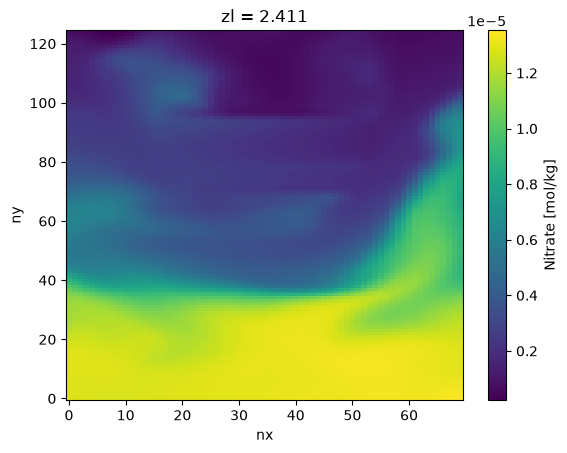

In [33]:
expt.init_tracers.no3.isel(zl = 0).plot()

## Step 5: Boundary conditions


In [34]:
expt.setup_ocean_state_boundaries(
    tmp_dir,
    ocean_varnames,
    arakawa_grid = "C",
    bgc_tracer_names = bgc_varnames,
    bathymetry_path = Path(f"{input_dir}/bathymetry.nc"),
    )

Processing north boundary velocity & tracers...Applying Arakawa C grid variable mapping, which is u-velocity on xq, yh; v-velocity on xh, yq; and tracers on xh, yh.
Done.
Processing south boundary velocity & tracers...Applying Arakawa C grid variable mapping, which is u-velocity on xq, yh; v-velocity on xh, yq; and tracers on xh, yh.
Done.
Processing east boundary velocity & tracers...Applying Arakawa C grid variable mapping, which is u-velocity on xq, yh; v-velocity on xh, yq; and tracers on xh, yh.
Done.
Processing west boundary velocity & tracers...Applying Arakawa C grid variable mapping, which is u-velocity on xq, yh; v-velocity on xh, yq; and tracers on xh, yh.
Done.
Saved BGC tracer no3 to file /g/data/tm70/hm6113/rom3-inputdirs/access-rom3-bgc/bgc/no3_obc_segment.nc
Saved BGC tracer fe to file /g/data/tm70/hm6113/rom3-inputdirs/access-rom3-bgc/bgc/fe_obc_segment.nc
Saved BGC tracer o2 to file /g/data/tm70/hm6113/rom3-inputdirs/access-rom3-bgc/bgc/o2_obc_segment.nc
Saved BGC tra

### Fix the boundary time stamps

regional-mom6 assumes the boundary data is daily: it labels the records 0, 1, 2, ... days since the start date. Our data is monthly, so we replace `time` in every boundary file with the real dates from the source data.

In [35]:
raw_time = xr.open_dataset(tmp_dir / f"{expt.boundaries[0]}_unprocessed.nc").time
days = (raw_time - np.datetime64(date_range[0])) / np.timedelta64(1, "D")
print(raw_time.values[:3], days.values[:3])

for f in list(bgc_dir.glob("forcing_obc_segment_*.nc")) + list(bgc_dir.glob("*_obc_segment.nc")):
    with netCDF4.Dataset(f, "a") as nc:
        nc["time"][:] = days.values
        nc["time"].units = f"days since {date_range[0]}"

['2012-12-16T12:00:00.000000000' '2013-01-16T12:00:00.000000000'
 '2013-02-15T00:00:00.000000000'] [-15.5  15.5  45. ]


### Plotting boundaries
Note: I think the 4 corners are meant to be land?

-1e+20 3.62004320777487e-05
land points: 525 ocean points: 10050


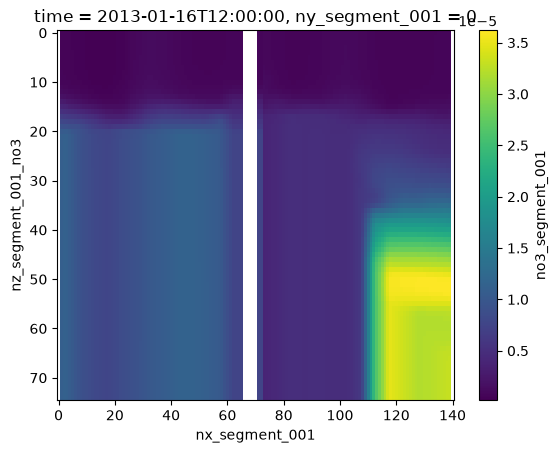

In [40]:
no3 = xr.open_dataset(bgc_dir / "no3_obc_segment.nc")
v = no3.no3_segment_001.isel(time=1).squeeze()
print(float(v.min()), float(v.max()))
print("land points:", int((v < -1e19).sum()), "ocean points:", int((v > -1e19).sum()))
v.where(v > -1e19).plot(yincrease=False)

Next step is to setup the experinment - we can almost just copy from the ACCESS-rOM3 demo - but someone needs to setup a stencil on access-om3 configs for this